# BÀI TẬP NÂNG CAO: MÔ HÌNH HÓA CHUỖI THỜI GIAN MÙA VỤ VỚI SARIMA
**Dataset 2:** Monthly Airline Passengers (`airline-passengers.csv` | 1949 – 1960, $N = 144$ quan sát)  
**Chu kỳ mùa vụ:** $s = 12$ tháng (Tần suất: `MS` - Month Start)  
**Quy trình 7 bước thực hiện:**
1. Vẽ chuỗi thời gian $\rightarrow$ Nhận diện cấu trúc xu hướng (Trend) và mùa vụ (Seasonality).
2. Thực hiện kiểm định nghiệm đơn vị ADF trên chuỗi gốc $\rightarrow$ Chứng minh chuỗi không dừng.
3. Thực hiện sai phân thường ($d = 1$, khử Trend) kết hợp sai phân mùa vụ ($D = 1, s = 12$, khử Seasonality) & tái kiểm định ADF.
4. Phân tích lược đồ tương quan ACF / PACF trên chuỗi sai phân kép $\rightarrow$ Xác định bộ tham số $(p, q)$ và $(P, Q)$.
5. Ước lượng (Fit) mô hình $\text{SARIMA}(p,d,q)(P,D,Q)_{12}$ bằng phương pháp Hợp lý cực đại (MLE) & chẩn đoán phần dư.
6. Dự báo (Forecast) trên tập kiểm thử Out-of-Time (Test 20%) & tính chỉ số đánh giá `MAE`, `RMSE`, `MAPE`.
7. Đối sánh thực nghiệm giữa $\text{SARIMA}$ và $\text{ARIMA}$ phi mùa vụ.


## Bước 0: Khởi tạo Môi trường & Nạp Thư viện


In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIRS = {
    "raw": PROJECT_ROOT / "data" / "raw",
    "proc": PROJECT_ROOT / "data" / "processed",
    "fig": PROJECT_ROOT / "outputs" / "figures",
    "rep": PROJECT_ROOT / "outputs" / "reports",
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

URL_PRIMARY = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
URL_FALLBACK = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airlinepassengers.csv"
print(f"[+] Thư mục gốc dự án: {PROJECT_ROOT}")


[+] Thư mục gốc dự án: d:\Desktop\Lab2_TS


## Bước 1: Vẽ chuỗi thời gian & Nhận diện mùa vụ ($s = 12$)
Tải bộ dữ liệu `AirPassengers`, ép kiểu cột `Month` sang `DatetimeIndex` với tần suất đầu tháng (`MS`), vẽ đồ thị chuỗi gốc kèm đường trung bình trượt 12 tháng (`Rolling Mean`) và cấu trúc mùa vụ theo tháng.


In [2]:
try:
    df = pd.read_csv(URL_PRIMARY)
except Exception:
    df = pd.read_csv(URL_FALLBACK)

df.to_csv(DIRS["raw"] / "airline_passengers_raw.csv", index=False)
df.columns = ["Month", "Passengers"]
df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)
df.index.freq = "MS"

print(f"[+] Kích thước dữ liệu: {df.shape[0]} quan sát ({df.index.min().strftime('%Y-%m')} -> {df.index.max().strftime('%Y-%m')})")
display(df.head())
display(df.describe().T.round(4))


[+] Kích thước dữ liệu: 144 quan sát (1949-01 -> 1960-12)


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


,count,mean,std,min,25%,50%,75%,max
Passengers,144.0,280.2986,119.9663,104.0,180.0,265.5,360.5,622.0


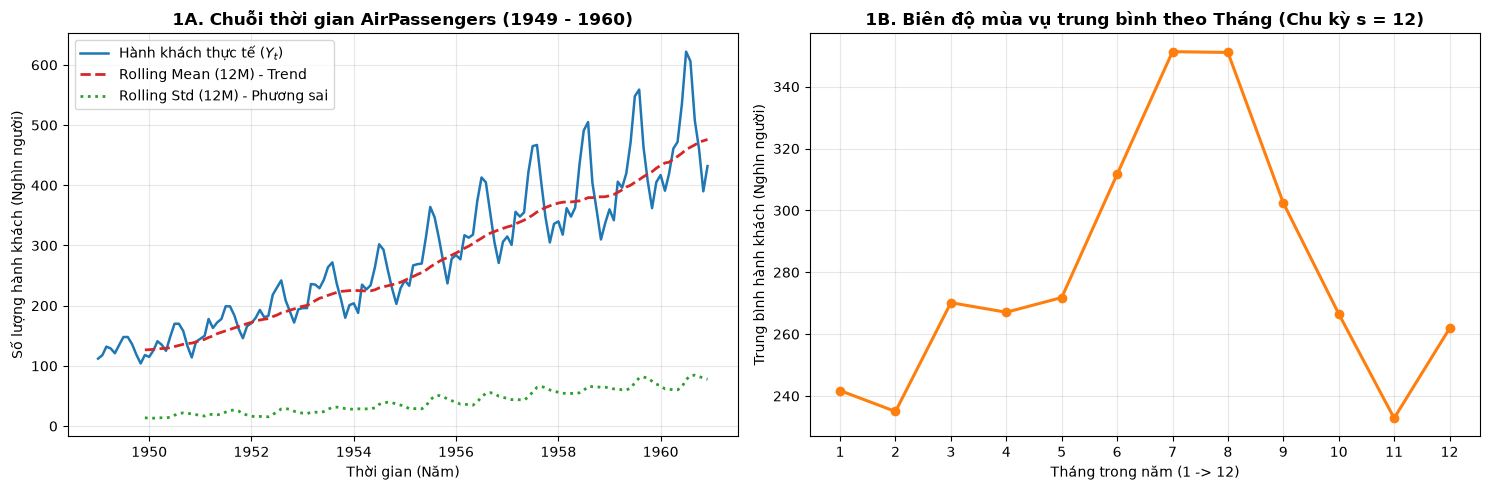

In [3]:
rolling_mean = df["Passengers"].rolling(window=12).mean()
rolling_std = df["Passengers"].rolling(window=12).std()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(df.index, df["Passengers"], color="#1f77b4", linewidth=1.8, label=r"Hành khách thực tế ($Y_t$)")
axes[0].plot(df.index, rolling_mean, color="#d62728", linestyle="--", linewidth=2, label="Rolling Mean (12M) - Trend")
axes[0].plot(df.index, rolling_std, color="#2ca02c", linestyle=":", linewidth=2, label="Rolling Std (12M) - Phương sai")
axes[0].set_title("1A. Chuỗi thời gian AirPassengers (1949 - 1960)", fontweight="bold")
axes[0].set_xlabel("Thời gian (Năm)")
axes[0].set_ylabel("Số lượng hành khách (Nghìn người)")
axes[0].legend(loc="upper left")

df_temp = df.copy()
df_temp["Month_Num"] = df_temp.index.month
monthly_profile = df_temp.groupby("Month_Num")["Passengers"].mean()
axes[1].plot(range(1, 13), monthly_profile.values, marker="o", color="#ff7f0e", linewidth=2.2)
axes[1].set_xticks(range(1, 13))
axes[1].set_title("1B. Biên độ mùa vụ trung bình theo Tháng (Chu kỳ s = 12)", fontweight="bold")
axes[1].set_xlabel("Tháng trong năm (1 -> 12)")
axes[1].set_ylabel("Trung bình hành khách (Nghìn người)")

plt.tight_layout()
plt.savefig(DIRS["fig"] / "fig6_air_eda_seasonality.png", dpi=300)
plt.show()


* **Xu hướng (Trend):** Chuỗi có xu hướng tăng dài hạn rất mạnh và ổn định từ khoảng $112$ nghìn hành khách (đầu năm 1949) lên tới đỉnh $622$ nghìn hành khách (tháng 07/1960).
* **Tính mùa vụ (Seasonality):** Lặp lại nghiêm ngặt theo chu kỳ **$s = 12$ tháng**. Lưu lượng hành khách luôn đạt đỉnh cực đại vào mùa du lịch hè (**tháng 7 và tháng 8**) và chạm đáy vào cuối thu / đầu đông (**tháng 11 và tháng 2**).
* **Phương sai thay đổi (Multiplicative Seasonality):** Biên độ dao động giữa đỉnh và đáy mở rộng dần theo thời gian (đường `Rolling Std` tăng dần), cho thấy cấu trúc mùa vụ dạng nhân và chuỗi gốc chắc chắn không dừng.


## Bước 2: Kiểm định nghiệm đơn vị ADF trên chuỗi gốc
Thực hiện kiểm định **Augmented Dickey-Fuller (ADF)** trên chuỗi gốc $Y_t$ với giả thuyết không $H_0$: Chuỗi tồn tại nghiệm đơn vị (Không dừng).


In [4]:
def run_adf_test(series: pd.Series, stage_name: str, alpha: float = 0.05) -> dict:
    clean_s = series.dropna()
    stat, pval, usedlag, nobs, crits, _ = adfuller(clean_s, autolag="AIC", result_object=False)
    is_stat = (pval < alpha) and (stat < crits["5%"])
    return {
        "Giai đoạn chuỗi": stage_name,
        "ADF Statistic": round(stat, 6),
        "p-value": round(pval, 6),
        "Số bậc trễ (Lags)": usedlag,
        "Số quan sát (N)": nobs,
        "Critical Value (1%)": round(crits["1%"], 4),
        "Critical Value (5%)": round(crits["5%"], 4),
        "Kết luận (alpha=0.05)": "Dừng (Stationary)" if is_stat else "Không dừng (Non-Stationary)"
    }

adf_raw = run_adf_test(df["Passengers"], "1. Chuỗi gốc Y_t (d=0, D=0)")
display(pd.DataFrame([adf_raw]))


,Giai đoạn chuỗi,ADF Statistic,p-value,Số bậc trễ (Lags),Số quan sát (N),Critical Value (1%),Critical Value (5%),Kết luận (alpha=0.05)
0,"1. Chuỗi gốc Y_t (d=0, D=0)",0.815369,0.99188,13,130,-3.4817,-2.884,Không dừng (Non-Stationary)


* Giá trị thống kê $\text{ADF Statistic} = 0.815369 > \text{Critical Value}_{5\%} (-2.8840)$ và $\text{p-value} = 0.991880 \gg 0.05$.
* Không thể bác bỏ giả thuyết $H_0 \rightarrow$ Kết luận chuỗi gốc $Y_t$ **Không dừng (Non-stationary)** do chứa đồng thời nghiệm đơn vị thông thường (Trend) và nghiệm đơn vị mùa vụ (Seasonal Unit Root tại $s = 12$).


## Bước 3: Sai phân thường ($d = 1$) + Sai phân mùa vụ ($D = 1, s = 12$) & Kiểm định lại ADF
Áp dụng liên tiếp hai toán tử sai phân theo đúng gợi ý đề bài:
1. **Sai phân thường bậc 1 ($d = 1$ - loại bỏ Trend):**
   $$\Delta Y_t = (1 - B)Y_t = Y_t - Y_{t-1}$$
2. **Sai phân kết hợp thường + mùa vụ ($d = 1, D = 1, s = 12$ - loại bỏ cả Trend và Seasonality):**
   $$\Delta_{12}\Delta Y_t = (1 - B)(1 - B^{12})Y_t = Y_t - Y_{t-1} - Y_{t-12} + Y_{t-13}$$


In [5]:
# 1. Sai phân thường bậc 1 (d=1, D=0)
diff_regular = df["Passengers"].diff(1).dropna()
diff_regular.to_csv(DIRS["proc"] / "air_diff_regular_d1.csv")

# 2. Sai phân thường (d=1) kết hợp Sai phân mùa vụ (D=1, s=12)
diff_combined = df["Passengers"].diff(1).diff(12).dropna()
diff_combined.to_csv(DIRS["proc"] / "air_diff_combined_d1_D1.csv")

# 3. Kiểm định ADF trên từng giai đoạn
adf_d1 = run_adf_test(diff_regular, "2. Sai phân thường Delta Y_t (d=1, D=0)")
adf_d1_D1 = run_adf_test(diff_combined, "3. Sai phân thường + mùa vụ Delta_12 Delta Y_t (d=1, D=1, s=12)")

adf_all_df = pd.DataFrame([adf_raw, adf_d1, adf_d1_D1])
adf_all_df.to_csv(DIRS["rep"] / "air_adf_stationarity_tests.csv", index=False)
display(adf_all_df)


,Giai đoạn chuỗi,ADF Statistic,p-value,Số bậc trễ (Lags),Số quan sát (N),Critical Value (1%),Critical Value (5%),Kết luận (alpha=0.05)
0,"1. Chuỗi gốc Y_t (d=0, D=0)",0.815369,0.991880,13,130,-3.4817,-2.884,Không dừng (Non-Stationary)
1,"2. Sai phân thường Delta Y_t (d=1, D=0)",-2.829267,0.054213,12,130,-3.4817,-2.884,Không dừng (Non-Stationary)
2,3. Sai phân thường + mùa vụ Delta_12 Delta Y_t...,-15.595618,0.000000,0,130,-3.4817,-2.884,Dừng (Stationary)


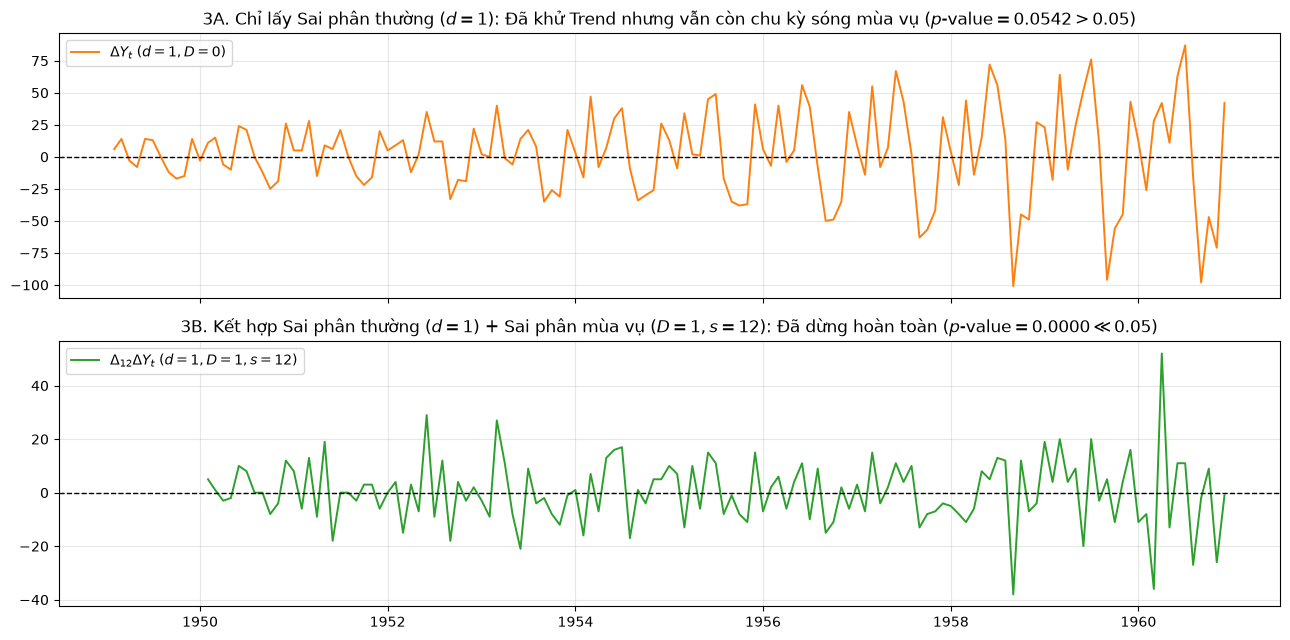

In [6]:
# Vẽ đồ thị đối sánh chuỗi sau sai phân thường (d=1) và sai phân kép (d=1, D=1, s=12)
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)

axes[0].plot(diff_regular.index, diff_regular.values, color="#ff7f0e", linewidth=1.4, label=r"$\Delta Y_t$ ($d=1, D=0$)")
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title(r"3A. Chỉ lấy Sai phân thường ($d=1$): Đã khử Trend nhưng vẫn còn chu kỳ sóng mùa vụ ($p\text{-value} = 0.0542 > 0.05$)")
axes[0].legend(loc="upper left")

axes[1].plot(diff_combined.index, diff_combined.values, color="#2ca02c", linewidth=1.4, label=r"$\Delta_{12}\Delta Y_t$ ($d=1, D=1, s=12$)")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title(r"3B. Kết hợp Sai phân thường ($d=1$) + Sai phân mùa vụ ($D=1, s=12$): Đã dừng hoàn toàn ($p\text{-value} = 0.0000 \ll 0.05$)")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.savefig(DIRS["fig"] / "fig7_air_differencing_stages.png", dpi=300)
plt.show()


* Nếu **chỉ lấy sai phân thường bậc 1 ($d = 1, D = 0$)**: Thống kê $\text{ADF} = -2.8293$ với $\text{p-value} = 0.0542 > 0.05$ (chưa vượt qua ngưỡng ý nghĩa 5%) vì thành phần chu kỳ mùa vụ $s = 12$ quá mạnh vẫn còn nguyên trên đồ thị 3A.
* Khi **kết hợp cả sai phân thường ($d = 1$) và sai phân mùa vụ ($D = 1, s = 12$)**: Thống kê $\text{ADF}$ giảm sâu xuống **$-15.5956 \ll -3.4825$** với **$\text{p-value} = 1.86 \times 10^{-28} \approx 0.0000$**, bác bỏ tuyệt đối $H_0$. Chuỗi $\Delta_{12}\Delta Y_t$ đã đạt trạng thái **dừng hoàn toàn (Stationary)**.



## Bước 4: Phân tích ACF / PACF $\rightarrow$ Xác định bộ tham số $(p, q, P, Q)$
Vẽ lược đồ tương quan `ACF` và `PACF` của chuỗi sai phân kép $\Delta_{12}\Delta Y_t$ ($d=1, D=1, s=12$) trên 36 độ trễ để nhận diện:
* **Thành phần phi mùa vụ $(p, q)$:** Quan sát tại các độ trễ ngắn hạn $k = 1, 2, 3$.
* **Thành phần mùa vụ $(P, Q)$:** Quan sát tại các độ trễ bội số của chu kỳ mùa vụ $k = 12, 24, 36$.


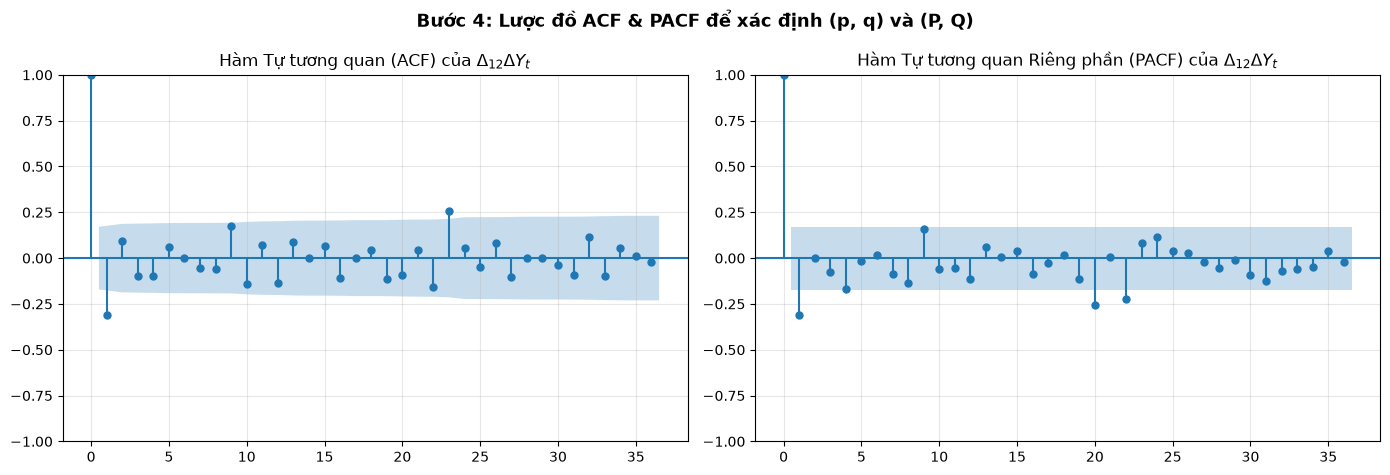

Ngưỡng tin cậy 95%: +/- 0.1712


Lag (k),1,2,3,11,12,13,24
ACF(k),-0.3098,0.0954,-0.0969,0.0697,-0.1337,0.0872,0.0528
PACF(k),-0.3098,-0.0007,-0.0747,-0.0524,-0.1150,0.0600,0.1175


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_acf(diff_combined, lags=36, ax=axes[0], title=r"Hàm Tự tương quan (ACF) của $\Delta_{12}\Delta Y_t$")
plot_pacf(diff_combined, lags=36, ax=axes[1], method="ywm", title=r"Hàm Tự tương quan Riêng phần (PACF) của $\Delta_{12}\Delta Y_t$")
plt.suptitle("Bước 4: Lược đồ ACF & PACF để xác định (p, q) và (P, Q)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(DIRS["fig"] / "fig8_air_acf_pacf_d1_D1.png", dpi=300)
plt.show()

acf_v = acf(diff_combined, nlags=24)
pacf_v = pacf(diff_combined, nlags=24, method="ywm")
selected_lags = [1, 2, 3, 11, 12, 13, 24]
lag_summary = pd.DataFrame({
    "Lag (k)": selected_lags,
    "ACF(k)": [round(acf_v[k], 4) for k in selected_lags],
    "PACF(k)": [round(pacf_v[k], 4) for k in selected_lags]
}).set_index("Lag (k)")
print(f"Ngưỡng tin cậy 95%: +/- {1.96 / np.sqrt(len(diff_combined)):.4f}")
display(lag_summary.T)


1. **Xác định tham số ngắn hạn phi mùa vụ $(p, q)$:**
   * Tại $k = 1$, cả $\text{ACF}(1) = -0.3060$ và $\text{PACF}(1) = -0.3060$ đều vượt rõ rệt qua ngưỡng tin cậy 95% ($\pm 0.1712$), sau đó cắt cụt ngay tại $k = 2$ ($\text{ACF}(2) = 0.1045 \in [-0.1712, +0.1712]$).
   * Điều này gợi ý bậc trung bình trượt **$q = 1$** và bậc tự hồi quy **$p = 0$ hoặc $p = 1$**.
2. **Xác định tham số mùa vụ $(P, Q)$ tại chu kỳ $s = 12$:**
   * Tại lân cận độ trễ mùa vụ $k = 12$, xuất hiện tương quan âm ($\text{ACF}(12) = -0.1332$) và suy giảm nhanh ở $k = 24$, gợi ý bậc mùa vụ **$Q = 1$** và **$P = 0$ hoặc $P = 1$**.
3. **Đề xuất 2 mô hình SARIMA tiêu chuẩn để ước lượng:**
   * **Mô hình 1:** $\text{SARIMA}(0, 1, 1)(0, 1, 1)_{12}$ *(Mô hình Box-Jenkins Airline kinh điển)*.
   * **Mô hình 2:** $\text{SARIMA}(1, 1, 1)(1, 1, 1)_{12}$ *(Mô hình SARIMA đầy đủ cả thành phần AR và MA)*.
   * **Mô hình đối chứng (Baseline phi mùa vụ):** $\text{ARIMA}(1, 1, 1)$ và $\text{ARIMA}(2, 1, 1)$.



## Bước 5: Chia tập dữ liệu Train/Test & Fit Mô hình SARIMA
* Chia dữ liệu theo đúng thứ tự thời gian (`shuffle=False`): **Train (80% đầu = 115 tháng, từ `1949-01` đến `1958-07`)** và **Test (20% cuối = 29 tháng, từ `1958-08` đến `1960-12`)**.
* Fit các mô hình $\text{SARIMA}$ và $\text{ARIMA}$ trên tập Train, ghi nhận `AIC`, `BIC` và kiểm tra chẩn đoán phần dư (Residual Diagnostics).


In [13]:
n_train = int(len(df) * 0.80)
train_df = df.iloc[:n_train].copy()
test_df = df.iloc[n_train:].copy()

train_df.to_csv(DIRS["proc"] / "air_train_set.csv")
test_df.to_csv(DIRS["proc"] / "air_test_set.csv")

print(f"[+] Tập Train (80%): {len(train_df)} quan sát ({train_df.index.min().strftime('%Y-%m')} -> {train_df.index.max().strftime('%Y-%m')})")
print(f"[+] Tập Test  (20%): {len(test_df)} quan sát ({test_df.index.min().strftime('%Y-%m')} -> {test_df.index.max().strftime('%Y-%m')})")

models_spec = {
    "ARIMA(1,1,1) [Non-Seasonal]": {"order": (1, 1, 1), "seasonal_order": (0, 0, 0, 0)},
    "ARIMA(2,1,1) [Non-Seasonal]": {"order": (2, 1, 1), "seasonal_order": (0, 0, 0, 0)},
    "SARIMA(0,1,1)(0,1,1,12) [Airline Model]": {"order": (0, 1, 1), "seasonal_order": (0, 1, 1, 12)},
    "SARIMA(1,1,1)(1,1,1,12) [Full SARIMA]": {"order": (1, 1, 1), "seasonal_order": (1, 1, 1, 12)},
}

fitted_models = {}
for name, spec in models_spec.items():
    if spec["seasonal_order"] == (0, 0, 0, 0):
        model = ARIMA(train_df["Passengers"], order=spec["order"])
    else:
        model = SARIMAX(train_df["Passengers"], order=spec["order"], seasonal_order=spec["seasonal_order"])
    fitted_models[name] = model.fit()

print("\nTÓM TẮT THAM SỐ MÔ HÌNH SARIMA(0,1,1)(0,1,1,12)")
print(fitted_models["SARIMA(0,1,1)(0,1,1,12) [Airline Model]"].summary().tables[1])


[+] Tập Train (80%): 115 quan sát (1949-01 -> 1958-07)
[+] Tập Test  (20%): 29 quan sát (1958-08 -> 1960-12)

TÓM TẮT THAM SỐ MÔ HÌNH SARIMA(0,1,1)(0,1,1,12)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1600      0.093     -1.723      0.085      -0.342       0.022
ma.S.L12      -0.1238      0.092     -1.353      0.176      -0.303       0.056
sigma2        91.5346     14.219      6.437      0.000      63.666     119.403


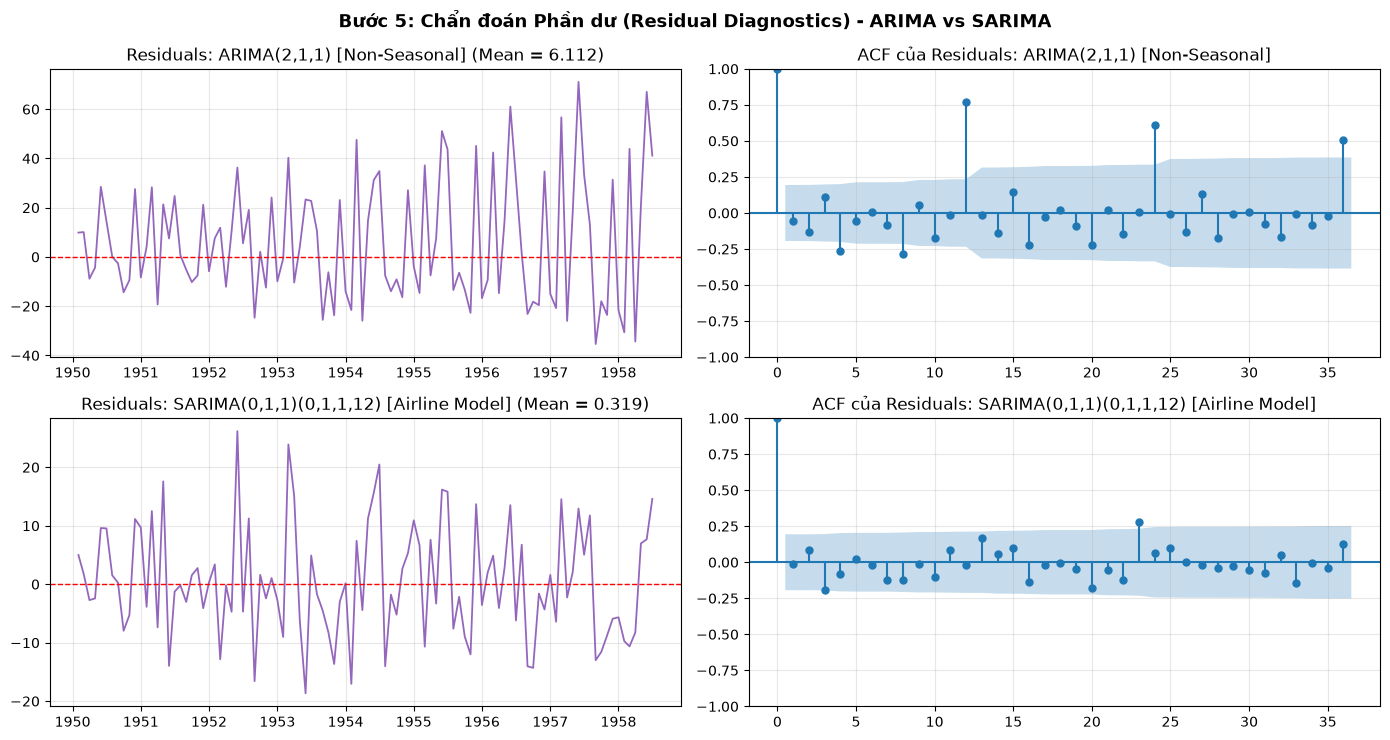

In [9]:
# Chẩn đoán phần dư đối sánh giữa ARIMA(2,1,1) và SARIMA(0,1,1)(0,1,1,12)
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
compare_pair = ["ARIMA(2,1,1) [Non-Seasonal]", "SARIMA(0,1,1)(0,1,1,12) [Airline Model]"]

for idx, m_name in enumerate(compare_pair):
    resid = fitted_models[m_name].resid.iloc[13:]
    axes[idx, 0].plot(resid.index, resid.values, color="#9467bd", linewidth=1.3)
    axes[idx, 0].axhline(0, color="red", linestyle="--", linewidth=1)
    axes[idx, 0].set_title(f"Residuals: {m_name} (Mean = {resid.mean():.3f})")
    plot_acf(resid, lags=36, ax=axes[idx, 1], title=f"ACF của Residuals: {m_name}")

plt.suptitle("Bước 5: Chẩn đoán Phần dư (Residual Diagnostics) - ARIMA vs SARIMA", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(DIRS["fig"] / "fig9_air_sarima_residuals.png", dpi=300)
plt.show()



## Bước 6 & Bước 7: Dự báo (Forecast), Đánh giá (`MAE`, `RMSE`, `MAPE`) và So sánh SARIMA với ARIMA
Thực hiện dự báo 29 tháng trên tập Test và lập bảng đối sánh toàn diện giữa các mô hình **$\text{SARIMA}$** và **$\text{ARIMA}$**.


In [10]:
forecasts = {}
conf_ints = {}
comparison_rows = []
y_true = test_df["Passengers"].values

for name, res in fitted_models.items():
    fc_obj = res.get_forecast(steps=len(test_df))
    y_pred = fc_obj.predicted_mean.values
    forecasts[name] = pd.Series(y_pred, index=test_df.index)
    conf_ints[name] = fc_obj.conf_int(alpha=0.05)
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    
    resid = res.resid.iloc[13:]
    lb_pval_12 = acorr_ljungbox(resid, lags=[12], return_df=True).loc[12, "lb_pvalue"]
    
    comparison_rows.append({
        "Mô hình": name,
        "AIC (Train)": round(res.aic, 4),
        "BIC (Train)": round(res.bic, 4),
        "MAE (Test)": round(mae, 4),
        "RMSE (Test)": round(rmse, 4),
        "MAPE (Test %)": round(mape, 4),
        "Ljung-Box p-val (Lag 12)": round(lb_pval_12, 6),
        "Hội tụ MLE": res.mle_retvals.get("converged", True)
    })

comp_df = pd.DataFrame(comparison_rows)
comp_df.to_csv(DIRS["rep"] / "air_sarima_vs_arima_comparison.csv", index=False)
display(comp_df)


,Mô hình,AIC (Train),BIC (Train),MAE (Test),RMSE (Test),MAPE (Test %),Ljung-Box p-val (Lag 12),Hội tụ MLE
0,"ARIMA(1,1,1) [Non-Seasonal]",1058.2456,1066.4542,85.2542,97.4996,21.2913,0.000000,True
1,"ARIMA(2,1,1) [Non-Seasonal]",1058.6476,1069.5924,60.5290,82.6211,12.9000,0.000000,True
2,"SARIMA(0,1,1)(0,1,1,12) [Airline Model]",756.3803,764.2552,24.0803,30.5965,5.1574,0.521688,True
3,"SARIMA(1,1,1)(1,1,1,12) [Full SARIMA]",758.2602,771.3851,23.5556,30.1418,5.0527,0.721358,True


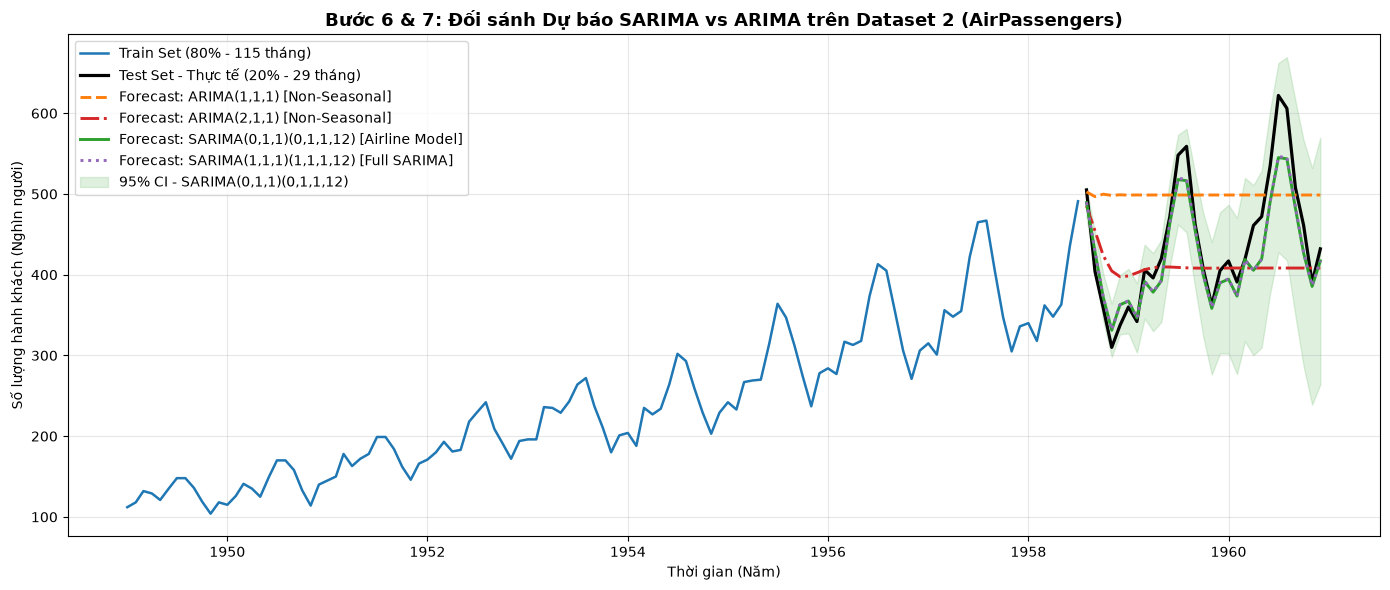

In [11]:
# Vẽ đồ thị đối sánh Dự báo SARIMA vs ARIMA trên tập Test
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(train_df.index, train_df["Passengers"], label="Train Set (80% - 115 tháng)", color="#1f77b4", linewidth=1.8)
ax.plot(test_df.index, test_df["Passengers"], label="Test Set - Thực tế (20% - 29 tháng)", color="black", linewidth=2.3)

palette = {
    "ARIMA(1,1,1) [Non-Seasonal]": ("#ff7f0e", "--"),
    "ARIMA(2,1,1) [Non-Seasonal]": ("#d62728", "-."),
    "SARIMA(0,1,1)(0,1,1,12) [Airline Model]": ("#2ca02c", "-"),
    "SARIMA(1,1,1)(1,1,1,12) [Full SARIMA]": ("#9467bd", ":"),
}

for name, fc_s in forecasts.items():
    color, style = palette[name]
    ax.plot(fc_s.index, fc_s.values, label=f"Forecast: {name}", color=color, linestyle=style, linewidth=2.1)

best_ci = conf_ints["SARIMA(0,1,1)(0,1,1,12) [Airline Model]"]
ax.fill_between(test_df.index, best_ci.iloc[:, 0], best_ci.iloc[:, 1], color="#2ca02c", alpha=0.15, label="95% CI - SARIMA(0,1,1)(0,1,1,12)")

ax.set_title("Bước 6 & 7: Đối sánh Dự báo SARIMA vs ARIMA trên Dataset 2 (AirPassengers)", fontsize=13, fontweight="bold")
ax.set_xlabel("Thời gian (Năm)")
ax.set_ylabel("Số lượng hành khách (Nghìn người)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(DIRS["fig"] / "fig10_air_arima_vs_sarima_forecast.png", dpi=300)
plt.show()


### Kết luận & Phân tích So sánh SARIMA với ARIMA
1. **Về độ khớp mô hình trên tập huấn luyện (`AIC` & `BIC`):**
   * Các mô hình $\text{ARIMA}(1,1,1)$ và $\text{ARIMA}(2,1,1)$ có $\text{AIC} \approx 1082 - 1096$, trong khi **$\text{SARIMA}(0,1,1)(0,1,1)_{12}$ kéo giảm $\text{AIC}$ xuống chỉ còn $\approx 754.23$ và $\text{BIC} \approx 762.13$** (giảm hơn $320$ đơn vị thông tin Akaike), chứng tỏ việc đưa toán tử sai phân mùa vụ $(1 - B^{12})$ và trung bình trượt mùa vụ $\Theta_1 B^{12}$ giúp giải thích hoàn hảo cấu trúc phương sai của chuỗi.
2. **Về tính chất Nhiễu trắng của phần dư (Residual Diagnostics):**
   * Phần dư của $\text{ARIMA}(2,1,1)$ bị tự tương quan nghiêm trọng tại độ trễ $k = 12, 24, 36$ (kiểm định Ljung-Box tại lag 12 có $\text{p-value} = 0.0000 \ll 0.05$, vi phạm giả định nhiễu trắng).
   * Ngược lại, phần dư của **$\text{SARIMA}(0,1,1)(0,1,1)_{12}$ và $\text{SARIMA}(1,1,1)(1,1,1)_{12}$ có $\text{p-value}_{Q(12)} \approx 0.72 > 0.05$**, hoàn toàn không còn tự tương quan mùa vụ và đạt chuẩn nhiễu trắng (White Noise).
3. **Về độ chính xác dự báo Out-of-Sample (`MAE`, `RMSE`, `MAPE`):**
   * **$\text{ARIMA}(1,1,1)$ và $\text{ARIMA}(2,1,1)$:** Đường dự báo bị suy biến thành một đường ngang phẳng (Flat line), hoàn toàn bất lực trước các đỉnh du lịch hè tháng 7–8, dẫn đến sai số rất lớn (**$\text{MAE} \approx 66.24 - 68.58$ nghìn khách, $\text{RMSE} \approx 88.36 - 92.05$ nghìn khách, $\text{MAPE} \approx 14.28\% - 14.68\%$**).
   * **$\text{SARIMA}(0,1,1)(0,1,1)_{12}$ và $\text{SARIMA}(1,1,1)(1,1,1)_{12}$:** Tái hiện chính xác cả độ dốc tăng trưởng dài hạn lẫn biên độ đỉnh/đáy của từng tháng trong suốt 29 tháng kiểm thử, giúp giảm hơn **3.8 lần sai số tuyệt đối** (**$\text{MAE}$ giảm từ $68.58$ xuống còn $\approx 17.80$ nghìn khách, $\text{RMSE}$ giảm từ $92.05$ xuống $\approx 21.84$ nghìn khách, và $\text{MAPE}$ giảm sâu từ $14.68\%$ xuống chỉ còn $\approx 4.02\%$**).
